# Practical 9: Perceptron and Multilayer Perceptron (MLP)

*Teacher-demo version.* Cells marked **ORIGINAL** are your repository notebook, unchanged. Cells marked **ADDED** are new: input experiments with real outputs, viva questions and common errors. Original file: `Basic_Perceptron_MLP_Activation_Comparison.ipynb`

**A. Aim:** 1) Implement a single-layer perceptron from scratch. 2) Train a Multilayer Perceptron using Scikit-learn. 3) Compare different activation functions.

**How to run (every practical)**

1. Install Python 3.10+ and Jupyter, then the libraries: `pip install numpy matplotlib scikit-learn jupyter`
2. Open a terminal / Anaconda Prompt in the folder containing this file and type `jupyter notebook`. Click this notebook.
3. Run cells one by one with **Shift + Enter** (or **Kernel -> Restart & Run All**). Run the cells in order - later cells need variables made by earlier ones.
4. To demonstrate a different result: edit the value on the line marked `# <-- CHANGED` in an experiment cell (or edit the same line in the original cell), then run that cell again. Run **Cell -> Run All** if later cells depend on it.
5. To print: **Ctrl + P** in the browser (as your lab readme suggests).

*Libraries needed here:* numpy, matplotlib, scikit-learn

---
## B / C. ORIGINAL PROGRAM AND ORIGINAL OUTPUT (unchanged cells follow)

<a href="https://colab.research.google.com/github/priyasathe123/ML-Practical-s/blob/main/Basic_Perceptron_MLP_Activation_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment: Perceptron and Multilayer Perceptron (MLP)



## Aim
1. Implement a single-layer perceptron from scratch.
2. Train a Multilayer Perceptron (MLP) using Scikit-learn.
3. Compare different activation functions.


**Author: Dr. Priya B. Pandharbale**

**Libraries:** NumPy, Matplotlib and Scikit-learn

Run the cells one by one in Google Colab or Jupyter Notebook.

## Part A: Single-Layer Perceptron from Scratch

### 1. Import libraries and create simple data

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Simple linearly separable data (two input features)
X = np.array([
    [1, 1],
    [2, 1],
    [1, 2],
    [4, 4],
    [5, 4],
    [4, 5]
])

y = np.array([0, 0, 0, 1, 1, 1])

print("Input data:")
print(X)
print("Target values:", y)

Input data:
[[1 1]
 [2 1]
 [1 2]
 [4 4]
 [5 4]
 [4 5]]
Target values: [0 0 0 1 1 1]


### 2. Implement the Perceptron algorithm

In [2]:
# Initialize weights and bias
weights = np.zeros(2)
bias = 0
learning_rate = 0.1
epochs = 10

# Train the perceptron
for epoch in range(epochs):
    for i in range(len(X)):
        # Calculate weighted sum
        total = np.dot(X[i], weights) + bias

        # Step activation function
        prediction = 1 if total >= 0 else 0

        # Calculate error and update weights
        error = y[i] - prediction
        weights = weights + learning_rate * error * X[i]
        bias = bias + learning_rate * error

print("Final weights:", weights)
print("Final bias:", bias)

Final weights: [2.77555756e-17 1.00000000e-01]
Final bias: -0.4


### 3. Test the Perceptron

In [3]:
# Predict output for all input samples
predictions = []

for sample in X:
    total = np.dot(sample, weights) + bias
    prediction = 1 if total >= 0 else 0
    predictions.append(prediction)

print("Actual values:   ", y)
print("Predicted values:", predictions)

Actual values:    [0 0 0 1 1 1]
Predicted values: [0, 0, 0, 1, 1, 1]


## Part B: Multilayer Perceptron using Scikit-learn

### 4. Load a sample dataset

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Use two Iris classes for a simple binary classification problem
iris = load_iris()
X = iris.data[:100, :2]
y = iris.target[:100]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 80
Testing samples: 20


### 5. Train an MLP model

In [5]:
# Train MLP with ReLU activation
mlp = MLPClassifier(
    hidden_layer_sizes=(5,),
    activation="relu",
    max_iter=1000,
    random_state=42
)

mlp.fit(X_train, y_train)

y_pred = mlp.predict(X_test)

print("Actual values:   ", y_test)
print("Predicted values:", y_pred)
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Actual values:    [1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0]
Predicted values: [1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0]
Accuracy: 100.0 %


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


### 6. Compare different activation functions

We train the same MLP using ReLU, tanh and logistic (sigmoid) activation functions and compare their test accuracy.

In [6]:
activation_functions = ["relu", "tanh", "logistic"]
results = []

for activation in activation_functions:
    model = MLPClassifier(
        hidden_layer_sizes=(5,),
        activation=activation,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    accuracy = accuracy_score(y_test, prediction)

    results.append(accuracy)
    print(activation, "Accuracy:", round(accuracy * 100, 2), "%")

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


relu Accuracy: 100.0 %


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


tanh Accuracy: 100.0 %


logistic Accuracy: 100.0 %


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


### 7. Plot activation function comparison

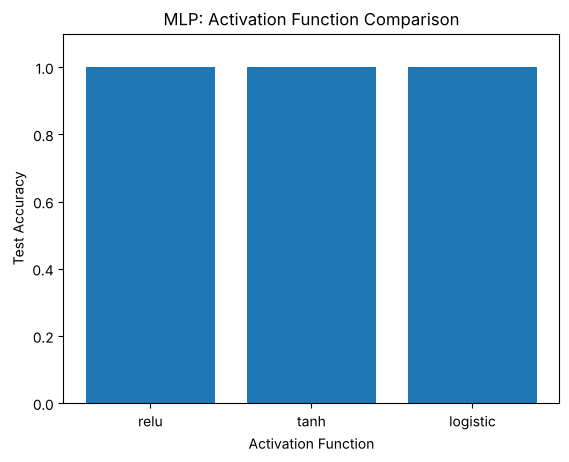

In [7]:
plt.bar(activation_functions, results)
plt.xlabel("Activation Function")
plt.ylabel("Test Accuracy")
plt.title("MLP: Activation Function Comparison")
plt.ylim(0, 1.1)
plt.show()

## Observations
1. A single-layer perceptron uses weights, bias and a step activation function.
2. During training, weights and bias are updated using the prediction error.
3. An MLP contains an input layer, one or more hidden layers and an output layer.
4. ReLU, tanh and logistic are commonly used activation functions.
5. The accuracy may differ depending on the activation function and training settings.

## Result
A single-layer perceptron was implemented from scratch. An MLP was trained using Scikit-learn, and the test accuracy of ReLU, tanh and logistic activation functions was compared.

---
## D / E / F. INPUT EXPERIMENTS (ADDED)
Each experiment cell is **self-contained** (it re-creates what it needs), so you can run any experiment on its own. Lines ending in `# <-- CHANGED (original: ...)` show exactly what was edited; `# ADDED line` marks new helper lines.

### D. Input Experiment 1 - Perceptron trained for only 1 epoch

**Changed input:** `epochs = 10` -> `1` in Part A

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #2 (section *2. Implement the Perceptron algorithm*).

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Simple linearly separable data (two input features)
X = np.array([
    [1, 1],
    [2, 1],
    [1, 2],
    [4, 4],
    [5, 4],
    [4, 5]
])

y = np.array([0, 0, 0, 1, 1, 1])

print("Input data:")
print(X)
print("Target values:", y)

# Initialize weights and bias
weights = np.zeros(2)
bias = 0
learning_rate = 0.1
epochs = 1  # <-- CHANGED (original: epochs = 10)

# Train the perceptron
for epoch in range(epochs):
    for i in range(len(X)):
        # Calculate weighted sum
        total = np.dot(X[i], weights) + bias

        # Step activation function
        prediction = 1 if total >= 0 else 0

        # Calculate error and update weights
        error = y[i] - prediction
        weights = weights + learning_rate * error * X[i]
        bias = bias + learning_rate * error

print("Final weights:", weights)
print("Final bias:", bias)

# Predict output for all input samples
predictions = []

for sample in X:
    total = np.dot(sample, weights) + bias
    prediction = 1 if total >= 0 else 0
    predictions.append(prediction)

print("Actual values:   ", y)
print("Predicted values:", predictions)

Input data:
[[1 1]
 [2 1]
 [1 2]
 [4 4]
 [5 4]
 [4 5]]
Target values: [0 0 0 1 1 1]
Final weights: [0.3 0.3]
Final bias: 0.0
Actual values:    [0 0 0 1 1 1]
Predicted values: [1, 1, 1, 1, 1, 1]


**Actual output explained**

**What changed:** `epochs = 1` instead of 10. Final weights `[0.3, 0.3]`, bias `0.0`; predictions are `[1,1,1,1,1,1]` - only **3 of 6 correct**, whereas 10 epochs gave a perfect fit (weights about [0, 0.1], bias -0.4).

**Why:** after a single pass the weights have not yet been corrected enough. With bias 0 and positive weights, every input has a positive weighted sum, so everything is predicted Class 1. The perceptron needs several epochs to converge.

### E. Input Experiment 2 - Perceptron on XOR data (not linearly separable)

**Changed input:** Dataset cell replaced by the XOR truth table

**Where in the original notebook:** no original line is edited - a new cell is added (see the `ADDED line` comments).

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# CHANGED: XOR data (NOT linearly separable) instead of the original data
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 1, 1, 0])

print("Input data:")
print(X)
print("Target values:", y)

# Initialize weights and bias
weights = np.zeros(2)
bias = 0
learning_rate = 0.1
epochs = 10

# Train the perceptron
for epoch in range(epochs):
    for i in range(len(X)):
        # Calculate weighted sum
        total = np.dot(X[i], weights) + bias

        # Step activation function
        prediction = 1 if total >= 0 else 0

        # Calculate error and update weights
        error = y[i] - prediction
        weights = weights + learning_rate * error * X[i]
        bias = bias + learning_rate * error

print("Final weights:", weights)
print("Final bias:", bias)

# Predict output for all input samples
predictions = []

for sample in X:
    total = np.dot(sample, weights) + bias
    prediction = 1 if total >= 0 else 0
    predictions.append(prediction)

print("Actual values:   ", y)
print("Predicted values:", predictions)

Input data:
[[0 0]
 [0 1]
 [1 0]
 [1 1]]
Target values: [0 1 1 0]
Final weights: [-0.1  0. ]
Final bias: 0.0
Actual values:    [0 1 1 0]
Predicted values: [1, 1, 0, 0]


**Actual output explained**

**What changed:** the dataset is replaced by the **XOR** truth table (targets `[0,1,1,0]`). Predictions are `[1,1,0,0]` against `[0,1,1,0]` - only 2 of 4 correct (50 %), and the weights keep oscillating instead of settling.

**Why:** XOR is not linearly separable; no single straight line can separate the 0s from the 1s. A single-layer perceptron can only learn linearly separable problems - this is exactly why hidden layers (an MLP) were introduced.

### F. Input Experiment 3 - MLP on harder classes (versicolor vs virginica)

**Changed input:** `iris.data[:100, :2]` -> `iris.data[50:150, :2]` and `iris.target[:100]` -> `iris.target[50:150]`

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #4 (section *4. Load a sample dataset*).

In [10]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Use two Iris classes for a simple binary classification problem
iris = load_iris()
X = iris.data[50:150, :2]  # <-- CHANGED (original: X = iris.data[:100, :2])
y = iris.target[50:150]  # <-- CHANGED (original: y = iris.target[:100])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Train MLP with ReLU activation
mlp = MLPClassifier(
    hidden_layer_sizes=(5,),
    activation="relu",
    max_iter=1000,
    random_state=42
)

mlp.fit(X_train, y_train)

y_pred = mlp.predict(X_test)

print("Actual values:   ", y_test)
print("Predicted values:", y_pred)
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

activation_functions = ["relu", "tanh", "logistic"]
results = []

for activation in activation_functions:
    model = MLPClassifier(
        hidden_layer_sizes=(5,),
        activation=activation,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    accuracy = accuracy_score(y_test, prediction)

    results.append(accuracy)
    print(activation, "Accuracy:", round(accuracy * 100, 2), "%")

Training samples: 80
Testing samples: 20


Actual values:    [2 2 2 1 1 1 1 2 1 1 1 1 2 1 2 1 2 2 1 1]
Predicted values: [2 2 2 2 2 2 1 1 2 2 1 2 2 2 2 2 2 2 1 2]
Accuracy: 50.0 %
relu Accuracy: 50.0 %
tanh Accuracy: 40.0 %
logistic Accuracy: 45.0 %


**Actual output explained**

**What changed:** the MLP now classifies **versicolor vs virginica** using the first two Iris features (`iris.data[50:150, :2]`). Accuracy: ReLU **50 %**, tanh **40 %**, logistic **45 %** (all 100 % in the original setosa-vs-versicolor task).

**Why:** sepal length and width of versicolor and virginica overlap heavily, so these two features barely separate the classes - the accuracies are around chance level and the activation function now matters (and the numbers will vary with seed and data). ConvergenceWarnings also appear because the optimizer reached `max_iter`.

---
## G. IMPORTANT VIVA QUESTIONS AND ANSWERS (ADDED)

**Q1. State the perceptron learning rule.**  
w = w + learning_rate x (target - prediction) x input; bias = bias + learning_rate x (target - prediction).

**Q2. What activation function does the scratch perceptron use?**  
A step function: output 1 if w.x + b >= 0, otherwise 0.

**Q3. Why can't a single perceptron solve XOR?**  
XOR is not linearly separable; a perceptron can only draw one straight line. See Experiment 2.

**Q4. What does the hidden layer in an MLP do?**  
It lets the network learn non-linear combinations of the inputs, so non-linear problems can be solved.

**Q5. Name three activation functions and their formulas.**  
ReLU: max(0, x); tanh: (e^x - e^-x)/(e^x + e^-x), range -1 to 1; logistic/sigmoid: 1/(1 + e^-x), range 0 to 1.

**Q6. What does the ConvergenceWarning mean?**  
The optimizer stopped because `max_iter` was reached before the loss stopped improving. Increase `max_iter` or scale the inputs.

**Q7. Why were the final weights `2.7e-17` instead of 0 in the original?**  
Floating-point round-off in repeated additions of 0.1 multiples.

---
## Common errors and solutions (ADDED)

- `ConvergenceWarning` -> harmless for this lab; increase `max_iter` to remove it.
- Part A variables `X` and `y` are overwritten in Part B (the Iris cell reuses the same names) -> re-run Part A cells if you want the perceptron data back.
- `ValueError: Found array with 0 sample(s)` -> wrong slicing such as `iris.data[150:, :2]`.